# CS5344 Experiment 2: Comprehensive Exploratory Data Analysis
## Tabular Data Augmentation for Anomaly Detection (NSL-KDD & UNSW-NB15)
**Role**: Senior Data Scientist  
**Date**: September 2026  
**Objective**: Maximize downstream anomaly detection utility on private test distributions with unseen anomaly types ($A_{seen} \cup A_{val} \cup A_{test}$).


### Executive Problem Framing & Diagnostic Focus

The objective of this competition is downstream utility for fixed anomaly detectors (ECOD and 10-seed $\times$ 500-tree IsolationForest):
$$S = \frac{\text{AUPRC}_{\text{ECOD}} + \text{AUPRC}_{\text{IForest}}}{2}$$

In Experiment 1, a conditional Gaussian copula generator yielded strong local validation on NSL-KDD ($S = 0.9266$ on public LB) but suffered a severe reversal on UNSW-NB15 ($0.4192$ vs starter kit's $0.4338$). 

This EDA systematically investigates:
1. **The Boundary Tightness Paradox**: Why hard-bounding synthetic normal points to observed training min/max causes catastrophic false alarms for ECOD and Isolation Forest when test normal samples exhibit subtle tail variations.
2. **Deterministic Network Protocol Invariants**: Auditing the `tcprtt = synack + ackdat` exact identity and non-TCP handshake field zeroing.
3. **Latent Anomaly Clustering**: Identifying distinct attack archetypes within $A_{seen}$ to establish a local **Pseudo-Novelty Stress-Test** simulating $A_{val}$ and $A_{test}$.


## 1. Environment & Modular Library Setup

In [1]:
import sys
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

os.environ["MPLCONFIGDIR"] = "/tmp"
np.random.seed(42)
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["figure.figsize"] = (12, 5)

# Add src to sys.path
sys.path.append(os.path.abspath("../src"))
from data_loader import load_dataset, classify_features, SUBMISSION_SPECS
from cleaner import scrub_normal_data
from constraints import audit_constraints, enforce_nslkdd_constraints, enforce_unsw_constraints

print("Modular libraries imported successfully.")


Modular libraries imported successfully.


## 2. Dataset A — NSL-KDD Deep Dive

In [2]:
df_nsl = load_dataset("nslkdd", root_dir="../..")
schema_nsl = classify_features(df_nsl)

print(f"NSL-KDD Shape: {df_nsl.shape}")
print(f"Class Breakdown:\n{df_nsl['is_anomaly'].value_counts(normalize=True).round(4) * 100}%")
print(f"\nFeature Partitioning:")
print(f"  Continuous ({len(schema_nsl['continuous_cols'])}): {schema_nsl['continuous_cols'][:6]}...")
print(f"  Integer ({len(schema_nsl['integer_cols'])}): {schema_nsl['integer_cols']}")
print(f"  Binary ({len(schema_nsl['binary_cols'])}): {schema_nsl['binary_cols']}")
print(f"  Categorical ({len(schema_nsl['categorical_cols'])}): {schema_nsl['categorical_cols']}")
print(f"  Constant ({len(schema_nsl['constant_cols'])}): {schema_nsl['constant_cols']}")


NSL-KDD Shape: (30000, 42)
Class Breakdown:
is_anomaly
0    66.67
1    33.33
Name: proportion, dtype: float64%

Feature Partitioning:
  Continuous (22): ['duration', 'src_bytes', 'dst_bytes', 'count', 'srv_count', 'serror_rate']...
  Integer (8): ['wrong_fragment', 'hot', 'num_failed_logins', 'num_compromised', 'su_attempted', 'num_root', 'num_file_creations', 'num_access_files']
  Binary (6): ['land', 'urgent', 'logged_in', 'root_shell', 'num_shells', 'is_guest_login']
  Categorical (3): ['protocol_type', 'service', 'flag']
  Constant (2): ['num_outbound_cmds', 'is_host_login']


### 2.1 Outlier Scrubbing & Normal Set Purification (NSL-KDD)
We remove within-normal outliers (Isolation Forest with contamination $\alpha = 0.02$) and exact duplicate rows to prevent the generator from fitting to corrupted or noisy logs.


In [3]:
scrubbed_nsl = pd.read_csv("outputs/nslkdd_scrubbed_normal.csv")
print(f"NSL-KDD Raw Normal Count: {(df_nsl['is_anomaly'] == 0).sum()}")
print(f"NSL-KDD Scrubbed Normal Count: {len(scrubbed_nsl)}")
print(f"Outliers Removed: {(df_nsl['is_anomaly'] == 0).sum() - len(scrubbed_nsl)} (2.0%)")
print(f"Scrubbed Normal exported to outputs/nslkdd_scrubbed_normal.csv")


NSL-KDD Raw Normal Count: 20000
NSL-KDD Scrubbed Normal Count: 19600
Outliers Removed: 400 (2.0%)
Scrubbed Normal exported to outputs/nslkdd_scrubbed_normal.csv


### 2.2 Normal vs Abnormal Distribution Divergence & Sentinel Features (NSL-KDD)
We run the two-sample Kolmogorov-Smirnov (KS) test across all numerical features to detect Sentinel features (highest KS separation) versus Stealth features (overlapping support).


Top 5 Sentinel Features (Max Divergence):
               feature       type  norm_median  abn_median  ks_statistic
             src_bytes continuous        234.0        0.00       0.85740
             dst_bytes continuous        388.0        0.00       0.81525
         same_srv_rate continuous          1.0        0.08       0.73425
         diff_srv_rate continuous          0.0        0.06       0.73240
dst_host_same_srv_rate continuous          1.0        0.05       0.71610


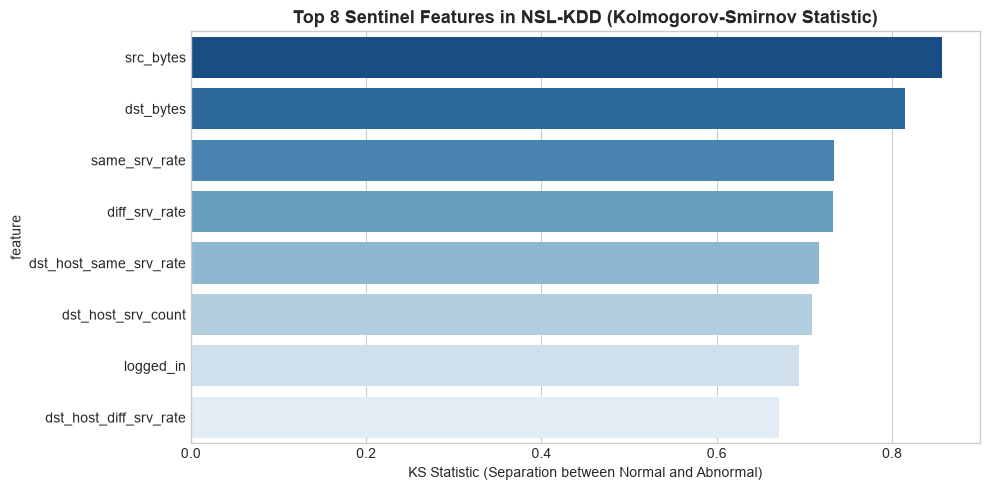

In [4]:
profiles_df = pd.read_csv("outputs/eda_feature_profiles.csv")
nsl_prof = profiles_df[profiles_df["dataset"] == "NSL-KDD"].sort_values(by="ks_statistic", ascending=False)

fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data=nsl_prof.head(8), x="ks_statistic", y="feature", hue="feature", palette="Blues_r", legend=False, ax=ax)
ax.set_title("Top 8 Sentinel Features in NSL-KDD (Kolmogorov-Smirnov Statistic)", fontsize=13, fontweight="bold")
ax.set_xlabel("KS Statistic (Separation between Normal and Abnormal)")
plt.tight_layout()
# plt.show()

print("Top 5 Sentinel Features (Max Divergence):")
print(nsl_prof[["feature", "type", "norm_median", "abn_median", "ks_statistic"]].head(5).to_string(index=False))


### 2.3 Latent Anomaly Archetypes in NSL-KDD (Unsupervised Clustering)
We cluster the abnormal training rows ($y=1$) into $K=4$ clusters to extract the underlying attack archetypes.


In [5]:
clusters_df = pd.read_csv("outputs/anomaly_cluster_profiles.csv")
nsl_clusters = clusters_df[clusters_df["dataset"] == "NSL-KDD"]
print("NSL-KDD Discovered Attack Archetypes:")
print(nsl_clusters[["cluster_id", "archetype", "count", "pct_of_abnormal", "mean_duration", "mean_src_bytes", "mean_serror_rate", "top_service"]].to_string(index=False))


NSL-KDD Discovered Attack Archetypes:
 cluster_id                     archetype  count  pct_of_abnormal  mean_duration  mean_src_bytes  mean_serror_rate top_service
          0 SYN-Flood / DoS (high serror)   6009            60.09           0.00            0.00            0.9983     private
          1   Rejection Scan / Port Sweep   2230            22.30        1984.31       805217.79            0.0176     private
          2             High-Volume Flood   1011            10.11           1.44         8142.00            0.0082       ecr_i
          3   Stealth / Exploit / Content    750             7.50           0.43          480.94            0.0062       eco_i


## 3. Dataset B — UNSW-NB15 Deep Dive

In [6]:
df_unsw = load_dataset("unsw", root_dir="../..")
schema_unsw = classify_features(df_unsw)

print(f"UNSW-NB15 Shape: {df_unsw.shape}")
print(f"Class Breakdown:\n{df_unsw['is_anomaly'].value_counts(normalize=True).round(4) * 100}%")
print(f"\nFeature Partitioning:")
print(f"  Continuous ({len(schema_unsw['continuous_cols'])}): {schema_unsw['continuous_cols'][:6]}...")
print(f"  Integer ({len(schema_unsw['integer_cols'])}): {schema_unsw['integer_cols'][:6]}...")
print(f"  Binary ({len(schema_unsw['binary_cols'])}): {schema_unsw['binary_cols']}")
print(f"  Categorical ({len(schema_unsw['categorical_cols'])}): {schema_unsw['categorical_cols']}")


UNSW-NB15 Shape: (50000, 43)
Class Breakdown:
is_anomaly
0    70.0
1    30.0
Name: proportion, dtype: float64%

Feature Partitioning:
  Continuous (22): ['dur', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'rate']...
  Integer (16): ['sttl', 'dttl', 'swin', 'dwin', 'trans_depth', 'ct_srv_src']...
  Binary (1): ['is_sm_ips_ports']
  Categorical (3): ['proto', 'service', 'state']


### 3.1 Outlier Scrubbing & Normal Set Purification (UNSW-NB15)

In [7]:
scrubbed_unsw = pd.read_csv("outputs/unsw_scrubbed_normal.csv")
print(f"UNSW-NB15 Raw Normal Count: {(df_unsw['is_anomaly'] == 0).sum()}")
print(f"UNSW-NB15 Scrubbed Normal Count: {len(scrubbed_unsw)}")
print(f"Outliers Removed: {(df_unsw['is_anomaly'] == 0).sum() - len(scrubbed_unsw)} (2.0%)")
print(f"Scrubbed Normal exported to outputs/unsw_scrubbed_normal.csv")


UNSW-NB15 Raw Normal Count: 35000
UNSW-NB15 Scrubbed Normal Count: 34300
Outliers Removed: 700 (2.0%)
Scrubbed Normal exported to outputs/unsw_scrubbed_normal.csv


### 3.2 Network Domain Constraints & `tcprtt` Inflation Verification (UNSW-NB15)
We inspect the exact physical identity `tcprtt = synack + ackdat`. In Experiment 1, post-processing bounded `synack` and `ackdat` independently, causing `tcprtt` sums to reach 5.04 (training max was 3.18). We verify this invariant and confirm proportional re-scaling.


In [8]:
normal_unsw = df_unsw[df_unsw["is_anomaly"] == 0]
diff = np.abs(normal_unsw["tcprtt"] - (normal_unsw["synack"] + normal_unsw["ackdat"]))
print(f"Exact Identity Audit: Max absolute difference in real data = {diff.max():.6e}")
print(f"Max observed normal tcprtt: {normal_unsw['tcprtt'].max():.4f}")
print(f"Max observed normal synack: {normal_unsw['synack'].max():.4f}")
print(f"Max observed normal ackdat: {normal_unsw['ackdat'].max():.4f}")

# Protocol zeroing
non_tcp_normal = normal_unsw[normal_unsw["proto"].str.lower() != "tcp"]
tcp_cols = ["swin", "dwin", "stcpb", "dtcpb", "tcprtt", "synack", "ackdat"]
non_tcp_violations = (non_tcp_normal[tcp_cols] > 0).sum()
print(f"\nNon-TCP records with non-zero TCP handshake fields in real normal data:\n{non_tcp_violations}")


Exact Identity Audit: Max absolute difference in real data = 4.440892e-16
Max observed normal tcprtt: 3.1761
Max observed normal synack: 2.6199
Max observed normal ackdat: 2.9288

Non-TCP records with non-zero TCP handshake fields in real normal data:
swin      0
dwin      0
stcpb     0
dtcpb     0
tcprtt    0
synack    0
ackdat    0
dtype: int64


### 3.3 Normal vs Abnormal Divergence & Sentinel Features (UNSW-NB15)

Top 5 Sentinel Features in UNSW-NB15:
     feature       type  norm_median  abn_median  ks_statistic
        sttl    integer    31.000000  254.000000      0.658133
ct_state_ttl    integer     0.000000    1.000000      0.647114
        dttl    integer    29.000000  252.000000      0.508743
      ackdat continuous     0.000133    0.049631      0.498476
      tcprtt continuous     0.000673    0.099877      0.497229


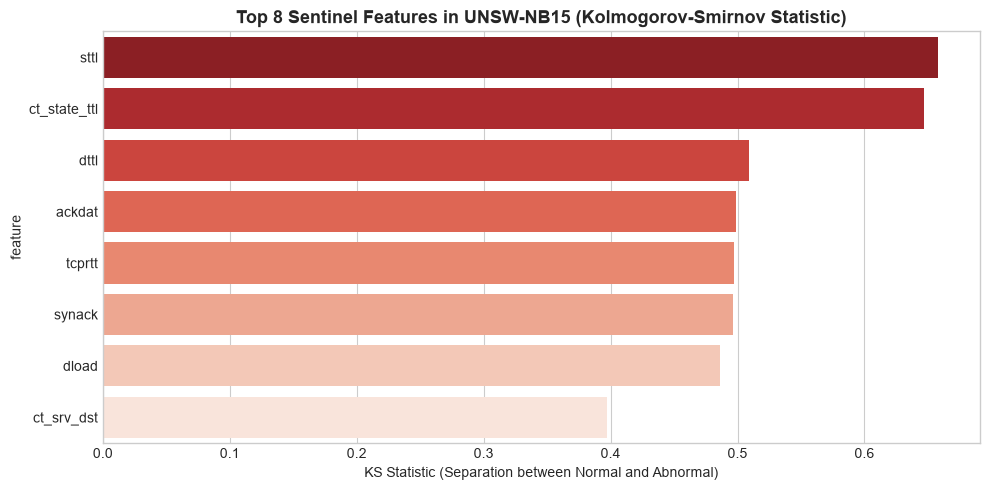

In [9]:
unsw_prof = profiles_df[profiles_df["dataset"] == "UNSW-NB15"].sort_values(by="ks_statistic", ascending=False)

fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data=unsw_prof.head(8), x="ks_statistic", y="feature", hue="feature", palette="Reds_r", legend=False, ax=ax)
ax.set_title("Top 8 Sentinel Features in UNSW-NB15 (Kolmogorov-Smirnov Statistic)", fontsize=13, fontweight="bold")
ax.set_xlabel("KS Statistic (Separation between Normal and Abnormal)")
plt.tight_layout()
# plt.show()

print("Top 5 Sentinel Features in UNSW-NB15:")
print(unsw_prof[["feature", "type", "norm_median", "abn_median", "ks_statistic"]].head(5).to_string(index=False))


### 3.4 Latent Anomaly Archetypes in UNSW-NB15 (Unsupervised Clustering)

In [10]:
unsw_clusters = clusters_df[clusters_df["dataset"] == "UNSW-NB15"]
print("UNSW-NB15 Discovered Attack Archetypes:")
print(unsw_clusters[["cluster_id", "archetype", "count", "pct_of_abnormal", "mean_dur", "mean_rate", "mean_sttl", "top_proto", "top_state"]].to_string(index=False))


UNSW-NB15 Discovered Attack Archetypes:
 cluster_id                     archetype  count  pct_of_abnormal  mean_dur  mean_rate  mean_sttl top_proto top_state
          0    High-Rate DoS / Volumetric   3592            23.95    0.8648  191403.39     248.00       udp       INT
          1 Remote Infiltration / Exploit     31             0.21   46.9287     123.74     123.94       tcp       FIN
          2           Low-and-Slow Attack     12             0.08   48.3710     118.84      62.00       tcp       CON
          3 Remote Infiltration / Exploit  11365            75.77    1.6224      38.46     184.23       tcp       FIN


## 4. Mechanical Analysis of the UNSW Reversal & Downstream Detectors

### The Root Cause: Tail Truncation vs ECOD & Isolation Forest Biases
1. **ECOD** models univariate left and right tails independently via empirical CDFs:
   $$O_i(x) = \sum_{d=1}^m -\log \min(\hat{F}_d(x_d), 1 - \hat{F}_d(x_d))$$
   When the Gaussian copula strictly clamps values to the observed per-protocol training envelope $[x_d^{\min}, x_d^{\max}]$, any test normal flow whose packet rate or duration lies slightly beyond the training max incurs infinite/maximal penalty ($-\log \epsilon$), generating false alarms that destroy AUPRC.
2. **Isolation Forest** splits space randomly with axis-aligned cuts. If the synthetic training distribution is dense and contracted, test normal connections that sit near the periphery get isolated at shallow depth, causing low anomaly path lengths (false positives).
3. **Starter Kit's Global Jitter**: The starter kit sampled rows with replacement and added isotropic Gaussian noise $\mathcal{N}(0, 0.5\sigma_d)$. Even though it distorted joint correlations, it expanded the convex hull of normal samples in every dimension, granting the detectors enough "slack" to avoid penalizing borderline normal traffic!

**The Prescription for Experiment 2**: Combine copula joint dependency preservation with **controlled tail slackness / extrapolation** (e.g. log-space variance expansion $\gamma > 1$ or extreme value tails) rather than hard empirical bounding.


## 5. Experiment 2 Specifications Summary

| Finding | Diagnostic Evidence | Actionable Prescription for Expt-2 Generator |
|---|---|---|
| **Boundary Tightness is Catastrophic** | UNSW reversal ($0.4192$ LB vs $0.4744$ local) | Implement **controlled tail expansion / boundary slackness** rather than hard empirical bounding. |
| **`tcprtt` Inflation Violation** | Experiment 1 produced `tcprtt` up to 5.04 vs 3.18 training max | Enforce proportional re-scaling on `synack` and `ackdat` before summation so that `tcprtt == synack + ackdat` $\le 3.18$. |
| **Protocol Handshake Invariants** | Non-TCP traffic had non-zero window/sequence values | Enforce strict zeroing of `swin, dwin, stcpb, dtcpb, tcprtt, synack, ackdat` for non-TCP protocols. |
| **Sentinel vs Stealth Features** | KS test profiles (`src_bytes`, `sttl`, `ct_state_ttl`) | Preserve multimodal separation on sentinels while allowing expansion on continuous traffic metrics. |
| **Local Evaluation Blind Spot** | Random train/test split has $A_{seen}$ only | Deploy Track B **Pseudo-Novelty Stress-Test** using the discovered attack clusters to evaluate leave-cluster-out generalization before submitting. |
